# Move-IIT-HPE — Experiment A: accuracy with valid 2D GT (revised protocol)

**Replacement for:** `MoveIIT_ExpA_2DGT_Analysis.ipynb`.

**Scope:** analyze the **existing** MoveEnet-only and MoveEnetOFK prediction CSV files, paired across 59 move-iit-hpe sequences and six neural-network periods. **No inference or event processing is performed.** The results are exported to a **new** folder, leaving the previous analysis intact.

### What changed, and what did not

- **Unchanged:** input prediction files, timestamp alignment (GT → prediction times), 13-joint output, right-shoulder/left-hip torso reference for PCK, six network rates, weighted aggregation, recording bootstrap, separate MPJPE/PCK figures, paired improvements and per-joint figure.
- **Fixed:** invalid 2D GT coordinates are masked **before** interpolation. A GT joint is usable only if both bracketing annotations are valid and close enough in time; prediction timestamps outside GT coverage are excluded. No interpolation through absent/out-of-frame markers and no endpoint holding.
- **Fixed:** MPJPE uses valid GT joint observations. PCK@0.2/0.4 additionally requires **both torso reference joints** to be valid and their distance nondegenerate. The *same joint masks* are applied to both methods at each paired timestamp.
- **Auditable:** GT invalidity and effective metric denominators are exported by sequence; the **legacy** unmasked metrics are computed separately to quantify the effect of the correction.

**Remaining assumptions, NOT validated by this notebook:** the projection-marker-to-HPE joint mapping and the GT time offset (default 0 s). Marker positions are proxies for anatomical joints. The notebook reads the existing projected 2D GT, not raw Vicon/3D data.

## 1. Paths, reproducibility and evaluation parameters

Use the **same source** as the previous Experiment A. The output directory is deliberately different; do not overwrite older results until the corrected numbers have been reviewed.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# -------- DATA / EXPERIMENT --------
BASE = Path('/data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA')
OUT = BASE / 'analysis_2d_gt_expa_masked_v2'
NETWORK_PERIODS = ('0.01', '0.02', '0.05', '0.1', '0.2', '0.5')
EXPECTED_SEQUENCES = 59
METHODS = ('moveenet_only', 'moveenet_ofk')

# -------- GT ALIGNMENT / VALIDITY --------
GT_TIME_OFFSET_S = 0.0  # GT sampled at prediction time + offset; still provisional
SENSOR_WIDTH, SENSOR_HEIGHT = 1280, 720
MAX_GT_GAP_S = 0.050  # 50 ms; prevents interpolation through long missing intervals
MIN_TORSO_PX = 1.0   # if torso ref is shorter, PCK for that timestamp is undefined
# Invalid GT = nonfinite OR outside sensor FOV; applied BEFORE interpolation.
# No endpoint hold: a prediction is evaluated only inside the available GT time span.

# -------- BOOTSTRAP / FIGURES --------
BOOTSTRAP_ITERATIONS = 1000
RANDOM_SEED = 12345
SAVE_FIGURES = True
FIGURE_FORMATS = ('svg', 'pdf', 'png')
DPI = 300
FIGSIZE = (7.5, 4.8)
FONT_SIZE = 12
LABEL_SIZE = 13
TICK_SIZE = 11
LEGEND_SIZE = 11
TITLE_SIZE = 13
LINE_WIDTH = 2.2
MARKER_SIZE = 7
SHOW_CI = True
COLORS = {'moveenet_only': '#375A9E', 'moveenet_ofk': '#D47A3C'}
MARKERS = {'moveenet_only': 's', 'moveenet_ofk': 'o'}
LABELS = {'moveenet_only': 'MoveEnet-only',
          'moveenet_ofk': 'MoveEnetOFK (ROI 35, flow 200 Hz)'}

plt.rcParams.update({
    'font.size': FONT_SIZE,
    'axes.labelsize': LABEL_SIZE,
    'axes.titlesize': TITLE_SIZE,
    'xtick.labelsize': TICK_SIZE,
    'ytick.labelsize': TICK_SIZE,
    'legend.fontsize': LEGEND_SIZE,
    'svg.fonttype': 'none',
    'pdf.fonttype': 42,
})

print('Input:', BASE)
print('Output (separate from legacy):', OUT)
print('GT interpolation: linear, per-joint, valid bracketing samples only')
print('Max GT bracketing gap:', MAX_GT_GAP_S, 's')
print('GT time offset:', GT_TIME_OFFSET_S, 's (PROVISIONAL)')

Input: /data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA
Output (separate from legacy): /data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA/analysis_2d_gt_expa_masked_v2
GT interpolation: linear, per-joint, valid bracketing samples only
Max GT bracketing gap: 0.05 s
GT time offset: 0.0 s (PROVISIONAL)


## 2. Verify the existing experiment manifest

Expected input: 59 paired recordings, with 6 neural periods and 2 methods (708 prediction CSVs). The GT files are the existing `*_joint_projections.csv`.

In [2]:
def require(condition, message):
    if not condition:
        raise RuntimeError(message)

manifest_path = BASE / 'manifest.csv'
require(manifest_path.is_file(), 'Missing manifest: {}'.format(manifest_path))
config_path = BASE / 'config.txt'
require(config_path.is_file(), 'Missing config: {}'.format(config_path))
config_text = config_path.read_text()
require('roi=35\n' in config_text and 'moveiit=true' in config_text,
        'Unexpected experiment configuration; expected ROI=35 and moveiit=true')
manifest = pd.read_csv(manifest_path, dtype=str)
require({'subject', 'sequence', 'events', 'ground_truth'} <= set(manifest.columns),
        'Unexpected manifest columns: {}'.format(list(manifest.columns)))
require(len(manifest) == EXPECTED_SEQUENCES,
        'Expected {} recordings, found {}'.format(EXPECTED_SEQUENCES, len(manifest)))
require(not manifest.duplicated(['subject', 'sequence']).any(),
        'Duplicate subject/sequence pairs')
print('Paired recordings:', len(manifest))
print('Expected prediction CSVs:', len(manifest) * len(NETWORK_PERIODS) * len(METHODS))
display(manifest[['subject', 'sequence', 'ground_truth']].head(6))

Paired recordings: 59
Expected prediction CSVs: 708


,subject,sequence,ground_truth
0,luna,box_f1,/data/move-iit-it_testing/GT/P1_luna/box_f1_jo...
1,luna,box_s1,/data/move-iit-it_testing/GT/P1_luna/box_s1_jo...
2,luna,drum_f1,/data/move-iit-it_testing/GT/P1_luna/drum_f1_j...
3,luna,drum_s1,/data/move-iit-it_testing/GT/P1_luna/drum_s1_j...
4,luna,march_f1,/data/move-iit-it_testing/GT/P1_luna/march_f1_...
5,luna,march_s1,/data/move-iit-it_testing/GT/P1_luna/march_s1_...


## 3. Read GT and predictions; validate GT **before** interpolation

The original CSV can include projected markers outside the 1280×720 field of view (for example the repeated coordinates observed for six markers in `luna/box_f1`). Such values are **not** valid targets.

The conversion from 2D GT marker order to hpe-core joint order remains the same as in the previous notebook and is **provisional**. It should be anatomically verified separately; this revision does not change the mapping.

In [3]:
JOINT_NAMES = (
    'Head', 'Right shoulder', 'Left shoulder', 'Right elbow', 'Left elbow',
    'Left hip', 'Right hip', 'Right wrist', 'Left wrist',
    'Right knee', 'Left knee', 'Right ankle', 'Left ankle'
)
# Original ExpA notebook mapping. PROVISIONAL; not a verified anatomical equivalence.
PROJECTION_TO_moveenet = np.array([0, 1, 2, 3, 4, 8, 7, 5, 6, 9, 10, 11, 12])
PRED_COLS = ['timestamp', 'latency'] + [
    'joint{}_{}'.format(j, axis) for j in range(13) for axis in 'xy'
]
seen_gt_schemas = {}


def load_gt(path):
    """Return original GT timestamps, mapped 2D joints, and RAW joint validity."""
    df = pd.read_csv(path, encoding='utf-8-sig')
    df.columns = [str(c).strip() for c in df.columns]
    df = df.loc[:, ~df.columns.str.match(r'^Unnamed: \d+$')]
    time_col = ('event_timestamp' if 'event_timestamp' in df.columns else
                'timestamp' if 'timestamp' in df.columns else df.columns[0])
    coord_cols = [c for c in df.columns if c != time_col]
    require(len(coord_cols) == 26,
            'GT must contain 13 (x,y) pairs: {} has {}'.format(path, coord_cols))
    for j in range(13):
        cx, cy = coord_cols[2*j:2*j+2]
        if cx.lower().endswith('_x') and cy.lower().endswith('_y'):
            require(cx[:-2].lower() == cy[:-2].lower(),
                    'Unpaired GT columns in {}: {} {}'.format(path, cx, cy))
    seen_gt_schemas.setdefault(tuple(coord_cols), []).append(str(path))
    times = pd.to_numeric(df[time_col], errors='raise').to_numpy(dtype=float)
    coords = df[coord_cols].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)
    require(len(times) >= 2 and np.isfinite(times).all() and
            np.all(np.diff(times) > 0), 'GT times not strictly increasing: {}'.format(path))

    native_order = all(coord_cols[2*j:2*j+2] ==
                       ['joint{}_x'.format(j), 'joint{}_y'.format(j)] for j in range(13))
    mapping = np.arange(13) if native_order else PROJECTION_TO_moveenet
    xy = coords.reshape(-1, 13, 2)[:, mapping, :]
    finite = np.isfinite(xy).all(axis=2)
    in_frame = (finite & (xy[..., 0] >= 0) & (xy[..., 0] < SENSOR_WIDTH) &
                (xy[..., 1] >= 0) & (xy[..., 1] < SENSOR_HEIGHT))
    return times, xy, in_frame, finite


def load_prediction(path):
    require(path.is_file(), 'Missing prediction CSV: {}'.format(path))
    df = pd.read_csv(path)
    require(list(df.columns[:28]) == PRED_COLS, 'Unexpected prediction columns: {}'.format(path))
    ts = pd.to_numeric(df.timestamp, errors='raise').to_numpy(dtype=float)
    xy = df[PRED_COLS[2:]].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float).reshape(-1, 13, 2)
    require(len(ts) >= 2 and np.isfinite(ts).all() and np.all(np.diff(ts) > 0),
            'Prediction timestamps not strictly increasing: {}'.format(path))
    return ts, xy


def masked_linear_gt(t_query, t_gt, xy_gt, valid_gt, max_gap_s=MAX_GT_GAP_S):
    """Linear interpolation per joint only between two valid neighboring GT samples.

    Outside the GT time span: invalid. At an exact sample: the sample is usable
    if valid, even if its neighboring sample is invalid. Otherwise both
    bracketing samples must be valid and their dt must be <= max_gap_s.
    """
    q = np.asarray(t_query, dtype=float) + GT_TIME_OFFSET_S
    t_gt = np.asarray(t_gt, dtype=float)
    valid_gt = np.asarray(valid_gt, dtype=bool)
    n, j = len(q), xy_gt.shape[1]
    result = np.full((n, j, 2), np.nan, dtype=float)
    mask = np.zeros((n, j), dtype=bool)
    inside = np.isfinite(q) & (q >= t_gt[0]) & (q <= t_gt[-1])
    if not inside.any():
        return result, mask, inside

    indices = np.flatnonzero(inside)
    query = q[indices]
    right = np.searchsorted(t_gt, query, side='left')
    right_clamped = np.minimum(right, len(t_gt)-1)
    exact = (right < len(t_gt)) & (np.abs(t_gt[right_clamped] - query) <= 1e-9)

    if exact.any():
        idx_q, idx_gt = indices[exact], right_clamped[exact]
        v = valid_gt[idx_gt]
        result[idx_q] = np.where(v[..., None], xy_gt[idx_gt], np.nan)
        mask[idx_q] = v

    between = ~exact
    if between.any():
        idx_q = indices[between]
        hi = right_clamped[between]
        lo = hi - 1
        dt = t_gt[hi] - t_gt[lo]
        okay_time = (dt > 0) & (dt <= max_gap_s)
        v = valid_gt[lo] & valid_gt[hi] & okay_time[:, None]
        alpha = ((query[between] - t_gt[lo]) / dt)[:, None, None]
        interpolated = xy_gt[lo] + alpha * (xy_gt[hi] - xy_gt[lo])
        result[idx_q] = np.where(v[..., None], interpolated, np.nan)
        mask[idx_q] = v
    return result, mask, inside


def legacy_interpolate_gt(t_query, t_gt, xy_gt):
    """Original, UNMASKED ExpA interpolation for diagnostic comparison only."""
    q = np.asarray(t_query, dtype=float) + GT_TIME_OFFSET_S
    result = np.empty((len(q), 13, 2), dtype=float)
    for j in range(13):
        for a in range(2):
            result[:, j, a] = np.interp(q, t_gt, xy_gt[:, j, a])
    return result

### Interpolation regression tests

These small synthetic tests run without the dataset. They ensure that the revised protocol does **not** bridge invalid GT markers, does not extrapolate outside the GT interval, and does not require an adjacent marker when a timestamp exactly matches a valid sample.

In [4]:
def test_masked_interpolation():
    t = np.array([0., .01, .02, .03])
    xy = np.zeros((4, 13, 2), dtype=float)
    xy[:, :, 0] = 100 + np.arange(4)[:, None] * 10
    xy[:, :, 1] = 200
    valid = np.ones((4, 13), dtype=bool)
    valid[1, 2] = False
    query = np.array([-.001, 0., .005, .01, .015, .02, .025, .031])
    interp, mask, inside = masked_linear_gt(query, t, xy, valid, max_gap_s=.05)
    assert not mask[0].any() and not mask[-1].any()
    assert mask[1].all() and mask[5].all()
    assert not mask[2, 2] and not mask[3, 2] and not mask[4, 2]
    assert mask[6, 2]
    assert np.isclose(interp[2, 0, 0], 105.)
    # A long temporal gap is rejected even when both GT markers are valid.
    distant = np.array([0., .1])
    dummy = np.zeros((2, 13, 2), dtype=float)
    _, m, _ = masked_linear_gt([.05], distant, dummy,
                               np.ones((2,13), bool), max_gap_s=.05)
    assert not m.any()
    print('PASS: masked GT interpolation, exact samples, no bridging/no extrapolation')

test_masked_interpolation()

PASS: masked GT interpolation, exact samples, no bridging/no extrapolation


## 4. Evaluate all prediction CSVs with a shared paired GT mask

For **MPJPE**, each valid joint contributes one observation. For **PCK**, the same joint must be valid **and** both torso-reference joints (indices 1, 5) must be valid with a nondegenerate distance. A single invalid shoulder does **not** invalidate an otherwise usable knee for MPJPE, but PCK at that timestamp is undefined.

Both methods must be evaluated at identical timestamps, with the **same** valid-joint mask and denominators. We do not interpolate predictions.

In [5]:
def safe_ratio(num, den, scale=1.0):
    return float(scale * num / den) if den > 0 else float('nan')

sample_rows, joint_rows, gt_quality_rows, comparison_rows = [], [], [], []

for i, rec in enumerate(manifest.itertuples(index=False), start=1):
    subject, sequence = rec.subject, rec.sequence
    gt_path = Path(rec.ground_truth)
    require(gt_path.is_file(), 'Missing GT: {}'.format(gt_path))
    gt_times, gt_coords, gt_valid_raw, gt_finite = load_gt(gt_path)
    gt_quality_rows.append({
        'subject': subject, 'sequence': sequence,
        'gt_rows': int(len(gt_times)),
        'gt_start_s': float(gt_times[0]), 'gt_end_s': float(gt_times[-1]),
        'gt_median_dt_ms': float(np.median(np.diff(gt_times)) * 1000),
        'gt_mean_hz': float((len(gt_times)-1) / (gt_times[-1]-gt_times[0])),
        'gt_nonfinite_annotations': int((~gt_finite).sum()),
        'gt_out_of_frame_annotations': int((gt_finite & ~gt_valid_raw).sum()),
        'gt_valid_annotations': int(gt_valid_raw.sum()),
        'gt_total_annotations': int(gt_valid_raw.size),
    })
    stem = '{}__{}__atis-s'.format(subject, sequence)
    for period_tag in NETWORK_PERIODS:
        period = float(period_tag)
        tag = period_tag.replace('.', 'p')
        csv_dir = BASE / 'raw' / 'fp_0p005' / ('np_' + tag)
        predictions = {}
        for method in METHODS:
            name = '{}_{}_np_{}_fp_0p005'.format(stem, method, tag)
            csv_path = csv_dir / (name + '.csv')
            log_path = BASE / 'logs' / (name + '.log')
            require(log_path.is_file() and
                    'Finished processing event file.' in log_path.read_text(errors='replace'),
                    'Missing/incomplete original run: {}'.format(log_path))
            predictions[method] = load_prediction(csv_path)

        ts = predictions[METHODS[0]][0]
        require(all(np.array_equal(ts, predictions[m][0]) for m in METHODS[1:]),
                'Predicted timestamps differ between methods: {} {} {}'.format(subject, sequence, period))
        gt_interp, gt_mask, time_in_gt = masked_linear_gt(ts, gt_times, gt_coords, gt_valid_raw)
        # Joint is usable only when BOTH model predictions at that joint are finite.
        pred_valid = np.ones(gt_mask.shape, dtype=bool)
        for method in METHODS:
            pred_valid &= np.isfinite(predictions[method][1]).all(axis=2)
        shared_valid = gt_mask & pred_valid

        # PCK torso reference: right shoulder index 1, left hip index 5.
        torso_valid = shared_valid[:, 1] & shared_valid[:, 5]
        safe_gt = np.where(shared_valid[..., None], gt_interp, 0.)
        torso_dist = np.linalg.norm(safe_gt[:, 1] - safe_gt[:, 5], axis=1)
        torso_valid &= np.isfinite(torso_dist) & (torso_dist >= MIN_TORSO_PX)
        pck_mask = shared_valid & torso_valid[:, None]
        n_mpjpe = int(shared_valid.sum())
        n_pck = int(pck_mask.sum())
        require(n_mpjpe > 0, 'No valid MPJPE GT: {} {} {}'.format(subject, sequence, period))

        for method in METHODS:
            pred_xy = predictions[method][1]
            safe_pred = np.where(shared_valid[..., None], pred_xy, 0.)
            err = np.linalg.norm(safe_pred - safe_gt, axis=2)
            hits02 = (err <= 0.2 * torso_dist[:, None]) & pck_mask
            hits04 = (err <= 0.4 * torso_dist[:, None]) & pck_mask
            err_sum = float(err[shared_valid].sum())
            n_hits02, n_hits04 = int(hits02.sum()), int(hits04.sum())
            row = {
                'subject': subject, 'sequence': sequence,
                'sample_id': '{}/{}'.format(subject, sequence),
                'method': method, 'net_period_s': period, 'net_hz': 1. / period,
                'roi': 35, 'flow_hz': 200, 'output_hz': 200,
                'output_rows': len(ts),
                'gt_time_covered_rows': int(time_in_gt.sum()),
                'rows_with_any_valid_gt': int(gt_mask.any(axis=1).sum()),
                'rows_with_valid_torso': int(torso_valid.sum()),
                'valid_rows': int(shared_valid.any(axis=1).sum()),
                'valid_joints': n_mpjpe,
                'valid_pck_joints': n_pck,
                'sum_error_px': err_sum,
                'correct_pck02': n_hits02, 'correct_pck04': n_hits04,
                'mpjpe_px': safe_ratio(err_sum, n_mpjpe),
                'pck02_percent': safe_ratio(n_hits02, n_pck, 100.),
                'pck04_percent': safe_ratio(n_hits04, n_pck, 100.),
            }
            sample_rows.append(row)
            for j, label in enumerate(JOINT_NAMES):
                jm, jp = shared_valid[:, j], pck_mask[:, j]
                joint_rows.append({
                    'subject': subject, 'sequence': sequence,
                    'method': method, 'net_hz': 1./period,
                    'joint': label,
                    'valid_joints': int(jm.sum()),
                    'valid_pck_joints': int(jp.sum()),
                    'sum_error_px': float(err[jm, j].sum()),
                    'correct_pck02': int(hits02[:, j].sum()),
                })

            # Recompute original metrics for audit only, without altering new masks.
            old_gt = legacy_interpolate_gt(ts, gt_times, gt_coords)
            old_valid = (np.isfinite(ts) & np.isfinite(old_gt).all(axis=(1,2)) &
                         np.logical_and.reduce([np.isfinite(predictions[m][1]).all(axis=(1,2)) for m in METHODS]))
            if old_valid.any():
                g = old_gt[old_valid]
                p = pred_xy[old_valid]
                legacy_err = np.linalg.norm(p-g, axis=2)
                legacy_torso = np.maximum(np.linalg.norm(g[:, 1]-g[:, 5], axis=1), 1e-6)
                comparison_rows.append({
                    'sample_id': '{}/{}'.format(subject, sequence),
                    'subject': subject, 'sequence': sequence,
                    'method': method, 'net_hz': 1./period,
                    'legacy_mpjpe_px': float(legacy_err.mean()),
                    'legacy_pck02_percent': float(100.*(legacy_err <= .2*legacy_torso[:,None]).mean()),
                    'corrected_mpjpe_px': row['mpjpe_px'],
                    'corrected_pck02_percent': row['pck02_percent'],
                    'legacy_joint_observations': int(legacy_err.size),
                    'corrected_joint_observations': n_mpjpe,
                    'corrected_pck_observations': n_pck,
                })

    print('[{:02d}/{:02d}] {}/{}: OK; GT out-of-frame joints={}'.format(
        i, len(manifest), subject, sequence,
        gt_quality_rows[-1]['gt_out_of_frame_annotations']))

samples = pd.DataFrame(sample_rows)
joints = pd.DataFrame(joint_rows)
gt_quality = pd.DataFrame(gt_quality_rows)
comparison = pd.DataFrame(comparison_rows)
require(len(samples) == len(manifest) * len(NETWORK_PERIODS) * len(METHODS),
        'Incomplete evaluation')
print('Analyzed {} runs. No inference was executed.'.format(len(samples)))
print('GT schema layouts detected:', len(seen_gt_schemas))
for schema, paths in seen_gt_schemas.items():
    print('  {} recordings; example {}; markers: {}'.format(
        len(paths), Path(paths[0]).name, ', '.join(schema[0::2])))
print('Total raw GT annotations outside sensor:', int(gt_quality.gt_out_of_frame_annotations.sum()))
print('Total GT annotations nonfinite:', int(gt_quality.gt_nonfinite_annotations.sum()))
display(samples[['net_hz', 'method', 'mpjpe_px', 'pck02_percent', 'valid_joints',
                 'valid_pck_joints']].head(8).round(3))

[01/59] luna/box_f1: OK; GT out-of-frame joints=198
[02/59] luna/box_s1: OK; GT out-of-frame joints=24
[03/59] luna/drum_f1: OK; GT out-of-frame joints=0
[04/59] luna/drum_s1: OK; GT out-of-frame joints=0
[05/59] luna/march_f1: OK; GT out-of-frame joints=12
[06/59] luna/march_s1: OK; GT out-of-frame joints=252
[07/59] luna/mix_f1: OK; GT out-of-frame joints=0
[08/59] luna/mix_s1: OK; GT out-of-frame joints=0
[09/59] luna/pour_f1: OK; GT out-of-frame joints=0
[10/59] luna/pour_s1: OK; GT out-of-frame joints=0
[11/59] luna/side_f1: OK; GT out-of-frame joints=0
[12/59] luna/side_s1: OK; GT out-of-frame joints=0
[13/59] luna/sit-drum_f1: OK; GT out-of-frame joints=342
[14/59] luna/sit-drum_s1: OK; GT out-of-frame joints=0
[15/59] luna/sit-mix_f1: OK; GT out-of-frame joints=0
[16/59] luna/sit-mix_s1: OK; GT out-of-frame joints=0
[17/59] luna/sit-pour_f1: OK; GT out-of-frame joints=0
[18/59] luna/sit-pour_s1: OK; GT out-of-frame joints=6
[19/59] luna/sit_f1: OK; GT out-of-frame joints=0
[20/

,net_hz,method,mpjpe_px,pck02_percent,valid_joints,valid_pck_joints
0,100.0,moveenet_only,54.641,31.592,27867,27573
1,100.0,moveenet_ofk,51.758,32.564,27867,27573
2,50.0,moveenet_only,54.443,31.538,27867,27573
3,50.0,moveenet_ofk,51.478,32.891,27867,27573
4,20.0,moveenet_only,54.357,31.803,27867,27573
5,20.0,moveenet_ofk,51.575,32.887,27867,27573
6,10.0,moveenet_only,54.593,31.890,27867,27573
7,10.0,moveenet_ofk,52.063,33.319,27867,27573


## 5. Aggregate metrics and 95% sequence-bootstrap confidence intervals

As in the previous ExpA, the main MPJPE/PCK results use **pooled valid joint observations**. Their denominators are now different because missing GT is excluded. Bootstrap resamples full recordings, not individual poses; estimates are undefined if a bootstrap draw contains no valid PCK reference.

In [6]:
rng = np.random.default_rng(RANDOM_SEED)
summary_rows = []

def finite_ci(values):
    finite = np.asarray(values, float)
    finite = finite[np.isfinite(finite)]
    if len(finite) == 0:
        return (float('nan'), float('nan'))
    return tuple(float(v) for v in np.quantile(finite, [.025, .975]))

for (period, method), group in samples.groupby(['net_period_s', 'method'], sort=True):
    error_sum = group.sum_error_px.sum()
    joint_n = int(group.valid_joints.sum())
    pck_n = int(group.valid_pck_joints.sum())
    result = {
        'method': method, 'net_period_s': period, 'net_hz': 1. / period,
        'n_sequences': len(group), 'valid_joints': joint_n,
        'valid_pck_joints': pck_n,
        'mpjpe_px': safe_ratio(error_sum, joint_n),
        'pck02_percent': safe_ratio(group.correct_pck02.sum(), pck_n, 100.),
        'pck04_percent': safe_ratio(group.correct_pck04.sum(), pck_n, 100.),
        'macro_mpjpe_px': float(group.mpjpe_px.mean()),
        'macro_pck02_percent': float(group.pck02_percent.mean()),
        'sequences_with_pck_gt': int((group.valid_pck_joints > 0).sum()),
    }
    ids = rng.integers(0, len(group), size=(BOOTSTRAP_ITERATIONS, len(group)))
    err_boot = group.sum_error_px.to_numpy()[ids].sum(axis=1)
    n_boot = group.valid_joints.to_numpy()[ids].sum(axis=1)
    pck_boot = group.correct_pck02.to_numpy()[ids].sum(axis=1)
    pn_boot = group.valid_pck_joints.to_numpy()[ids].sum(axis=1)
    mp_boot = np.divide(err_boot, n_boot, out=np.full(len(ids), np.nan), where=n_boot > 0)
    pc_boot = np.divide(100.*pck_boot, pn_boot, out=np.full(len(ids), np.nan), where=pn_boot > 0)
    result['mpjpe_px_ci_low'], result['mpjpe_px_ci_high'] = finite_ci(mp_boot)
    result['pck02_percent_ci_low'], result['pck02_percent_ci_high'] = finite_ci(pc_boot)
    summary_rows.append(result)
summary = pd.DataFrame(summary_rows).sort_values(['net_hz', 'method']).reset_index(drop=True)
display(summary[['net_hz', 'method', 'n_sequences', 'mpjpe_px', 'pck02_percent',
                 'valid_joints', 'valid_pck_joints', 'sequences_with_pck_gt']].round(3))

,net_hz,method,n_sequences,mpjpe_px,pck02_percent,valid_joints,valid_pck_joints,sequences_with_pck_gt
0,2.0,moveenet_ofk,59,62.800,33.515,1568713,1567227,59
1,2.0,moveenet_only,59,67.746,29.879,1568713,1567227,59
2,5.0,moveenet_ofk,59,59.714,35.826,1568713,1567227,59
3,5.0,moveenet_only,59,62.673,34.312,1568713,1567227,59
4,10.0,moveenet_ofk,59,59.218,36.609,1568713,1567227,59
5,10.0,moveenet_only,59,61.836,35.930,1568713,1567227,59
6,20.0,moveenet_ofk,59,58.416,37.157,1568713,1567227,59
7,20.0,moveenet_only,59,61.205,36.620,1568713,1567227,59
8,50.0,moveenet_ofk,59,58.057,37.345,1568713,1567227,59
9,50.0,moveenet_only,59,61.075,36.705,1568713,1567227,59


## 6. Paired improvement — MoveEnetOFK relative to MoveEnet-only

Positive MPJPE reduction or PCK improvement means MoveEnetOFK performed better. Both methods use **exactly the same** denominators and GT masks per sequence and period.

In [7]:
delta_rows = []
for period in sorted(samples.net_period_s.unique()):
    group = samples[samples.net_period_s == period]
    ofk = group[group.method == 'moveenet_ofk'].set_index('sample_id').sort_index()
    net = group[group.method == 'moveenet_only'].set_index('sample_id').sort_index()
    require(ofk.index.equals(net.index), 'Unpaired recording identifiers')
    require(np.array_equal(ofk.valid_joints.to_numpy(), net.valid_joints.to_numpy()) and
            np.array_equal(ofk.valid_pck_joints.to_numpy(), net.valid_pck_joints.to_numpy()),
            'GT masks differ between methods')
    dmp = net.mpjpe_px.to_numpy() - ofk.mpjpe_px.to_numpy()
    dpc = ofk.pck02_percent.to_numpy() - net.pck02_percent.to_numpy()
    delta_rows.append({
        'net_period_s': period, 'net_hz': 1./period, 'n_sequences': len(ofk),
        'pooled_mpjpe_reduction_px': safe_ratio(net.sum_error_px.sum(), net.valid_joints.sum()) -
                                     safe_ratio(ofk.sum_error_px.sum(), ofk.valid_joints.sum()),
        'pooled_pck_improvement_pp': 100.*(
            safe_ratio(ofk.correct_pck02.sum(), ofk.valid_pck_joints.sum()) -
            safe_ratio(net.correct_pck02.sum(), net.valid_pck_joints.sum())),
        'mean_sequence_mpjpe_reduction_px': float(np.nanmean(dmp)),
        'mean_sequence_pck_improvement_pp': float(np.nanmean(dpc)) if np.isfinite(dpc).any() else float('nan'),
        'n_sequences_better_mpjpe': int((dmp > 0).sum()),
        'n_sequences_better_pck02': int((dpc > 0).sum()),
        'n_sequences_evaluable_pck02': int(np.isfinite(dpc).sum()),
    })
deltas = pd.DataFrame(delta_rows).sort_values('net_hz').reset_index(drop=True)
display(deltas[['net_hz', 'pooled_mpjpe_reduction_px',
                'pooled_pck_improvement_pp', 'n_sequences_better_mpjpe',
                'n_sequences_better_pck02', 'n_sequences_evaluable_pck02']].round(3))

,net_hz,pooled_mpjpe_reduction_px,pooled_pck_improvement_pp,n_sequences_better_mpjpe,n_sequences_better_pck02,n_sequences_evaluable_pck02
0,2.0,4.947,3.637,59,57,59
1,5.0,2.959,1.515,59,54,59
2,10.0,2.618,0.680,59,42,59
3,20.0,2.788,0.537,59,35,59
4,50.0,3.018,0.640,59,35,59
5,100.0,3.020,0.677,59,39,59


## 7. Data-quality and legacy-versus-corrected diagnostics

The original results remain available as a **diagnostic**, not as the revised main accuracy estimate. The table below shows which GT markers were invalid and how much the corrected denominators differ from the old finite-only protocol.

In [8]:
quality = gt_quality.copy()
quality['invalid_gt_fraction'] = 1.0 - quality.gt_valid_annotations / quality.gt_total_annotations
quality = quality.sort_values(['invalid_gt_fraction', 'subject', 'sequence'], ascending=[False, True, True])
print('Most affected GT recordings:')
display(quality[['subject', 'sequence', 'gt_rows', 'gt_mean_hz',
                 'gt_out_of_frame_annotations', 'gt_nonfinite_annotations',
                 'invalid_gt_fraction']].head(15).round(4))
comparison['delta_mpjpe_px'] = comparison.corrected_mpjpe_px - comparison.legacy_mpjpe_px
comparison['delta_pck02_pp'] = comparison.corrected_pck02_percent - comparison.legacy_pck02_percent
print('Selected comparison: 5 Hz (network period 0.2 s), first 12 recordings:')
display(comparison[np.isclose(comparison.net_hz, 5.0)][[
    'sample_id', 'method', 'legacy_mpjpe_px', 'corrected_mpjpe_px',
    'legacy_pck02_percent', 'corrected_pck02_percent',
    'corrected_joint_observations', 'corrected_pck_observations']].head(12).round(3))

# Show how often the chosen torso was valid for PCK at each network rate.
coverage = samples.groupby(['net_hz', 'method'], as_index=False).agg(
    n_rows=('output_rows', 'sum'), torso_rows=('rows_with_valid_torso', 'sum'),
    mpjpe_joints=('valid_joints', 'sum'), pck_joints=('valid_pck_joints', 'sum'))
coverage['pck_torso_row_coverage_pct'] = 100.*coverage.torso_rows / coverage.n_rows
print('Effective PCK coverage:')
display(coverage[['net_hz', 'method', 'n_rows', 'torso_rows',
                  'pck_torso_row_coverage_pct', 'mpjpe_joints', 'pck_joints']].round(2))

Most affected GT recordings:


,subject,sequence,gt_rows,gt_mean_hz,gt_out_of_frame_annotations,gt_nonfinite_annotations,invalid_gt_fraction
37,simon,monkey_s1,1619,99.8753,472,0,0.0224
36,simon,monkey_f1,1681,99.8804,400,0,0.0183
12,luna,sit-drum_f1,1665,99.8790,342,0,0.0158
30,simon,jump_f2,1641,99.8048,249,0,0.0117
5,luna,march_s1,1742,99.8266,252,0,0.0111
27,simon,box_s1,1587,99.7963,210,0,0.0102
31,simon,jump_s2,1599,99.7990,201,0,0.0097
20,luna,skater_f1,1729,99.8135,204,0,0.0091
0,luna,box_f1,1728,99.8249,198,0,0.0088
44,simon,sit-drum_f1,1566,99.8073,78,0,0.0038


Selected comparison: 5 Hz (network period 0.2 s), first 12 recordings:


,sample_id,method,legacy_mpjpe_px,corrected_mpjpe_px,legacy_pck02_percent,corrected_pck02_percent,corrected_joint_observations,corrected_pck_observations
8,luna/box_f1,moveenet_only,61.145,55.380,31.875,31.534,27867,27573
9,luna/box_f1,moveenet_ofk,58.214,52.415,33.955,33.656,27867,27573
20,luna/box_s1,moveenet_only,84.726,83.244,20.580,20.599,27650,27599
21,luna/box_s1,moveenet_ofk,81.306,79.811,20.839,20.809,27650,27599
32,luna/drum_f1,moveenet_only,41.112,41.130,32.419,32.431,28041,28041
33,luna/drum_f1,moveenet_ofk,38.230,38.248,37.032,37.014,28041,28041
44,luna/drum_s1,moveenet_only,36.291,36.200,39.806,39.919,27586,27586
45,luna/drum_s1,moveenet_ofk,34.253,34.155,42.792,42.913,27586,27586
56,luna/march_f1,moveenet_only,65.341,63.925,29.001,28.924,26788,26767
57,luna/march_f1,moveenet_ofk,61.866,60.442,29.885,29.805,26788,26767


Effective PCK coverage:


,net_hz,method,n_rows,torso_rows,pck_torso_row_coverage_pct,mpjpe_joints,pck_joints
0,2.0,moveenet_ofk,121365,120720,99.47,1568713,1567227
1,2.0,moveenet_only,121365,120720,99.47,1568713,1567227
2,5.0,moveenet_ofk,121365,120720,99.47,1568713,1567227
3,5.0,moveenet_only,121365,120720,99.47,1568713,1567227
4,10.0,moveenet_ofk,121365,120720,99.47,1568713,1567227
5,10.0,moveenet_only,121365,120720,99.47,1568713,1567227
6,20.0,moveenet_ofk,121365,120720,99.47,1568713,1567227
7,20.0,moveenet_only,121365,120720,99.47,1568713,1567227
8,50.0,moveenet_ofk,121365,120720,99.47,1568713,1567227
9,50.0,moveenet_only,121365,120720,99.47,1568713,1567227


## 8. Export corrected tables and the documented protocol

`analysis_2d_gt_expa_masked_v2/` is a **new** folder. Existing tables/plots from the earlier version are not overwritten.

In [9]:
OUT.mkdir(parents=True, exist_ok=True)
samples.to_csv(OUT / 'accuracy_by_sample.csv', index=False)
summary.to_csv(OUT / 'accuracy_summary.csv', index=False)
deltas.to_csv(OUT / 'paired_improvements.csv', index=False)
joints.to_csv(OUT / 'accuracy_by_joint_by_sample.csv', index=False)
gt_quality.to_csv(OUT / 'ground_truth_quality.csv', index=False)
comparison.to_csv(OUT / 'legacy_vs_corrected_by_sample.csv', index=False)
coverage.to_csv(OUT / 'metric_coverage.csv', index=False)

protocol = {
    'version': 'moveiit_expa_masked_v2',
    'dataset': 'move-iit-hpe', 'native_resolution': [SENSOR_WIDTH, SENSOR_HEIGHT],
    'n_sequences': len(manifest), 'network_periods_s': NETWORK_PERIODS,
    'flow_hz': 200, 'output_hz': 200, 'roi': 35,
    'gt_source': 'Existing 2D joint_projections.csv; no raw Vicon/3D data',
    'gt_time_offset_s': GT_TIME_OFFSET_S,
    'gt_interpolation': 'Linear per-joint at original prediction timestamps; no prediction interpolation',
    'gt_invalidity': 'Joint outside [0,W)x[0,H) or nonfinite, checked BEFORE interpolation',
    'gt_bracketing': 'Two nearest adjacent original GT samples must both be valid for a joint',
    'gt_exact_samples': 'Accepted if valid; no second bracketing neighbor needed',
    'gt_max_gap_s': MAX_GT_GAP_S,
    'gt_extrapolation': 'Forbidden; prediction timestamps outside GT span invalid',
    'mpjpe': 'Mean Euclidean error over shared, valid GT/predicted JOINT observations',
    'pck_reference_joints': [1, 5],
    'pck_min_torso_px': MIN_TORSO_PX,
    'pck': 'GT joints 1 and 5 must be valid; error <= alpha*torso distance; only valid target joints',
    'paired_denominators': 'Intersection of GT validity and both methods prediction finite masks',
    'aggregation': 'Pooled valid joint observations across recordings',
    'confidence_interval': '{} clustered recording bootstrap iterations; percentile 95%'.format(BOOTSTRAP_ITERATIONS),
    'seed': RANDOM_SEED,
    'gt_projection_to_moveenet_provisional': PROJECTION_TO_moveenet.tolist(),
    'validation_note': 'GT projection mapping and zero time offset remain PROVISIONAL; verify anatomical equivalence',
    'legacy_comparison': 'Previous unmasked and endpoint-held GT interpolation, exported separately for audit',
}
(OUT / 'evaluation_protocol.json').write_text(json.dumps(protocol, indent=2) + '\n')
print('Saved corrected results to:', OUT)

Saved corrected results to: /data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA/analysis_2d_gt_expa_masked_v2


## 9. Figure 1 — PCK@0.2 vs network inference frequency

The PCK denominator includes only joints for which the GT torso is valid; changing the denominator is expected and documented in `metric_coverage.csv`.

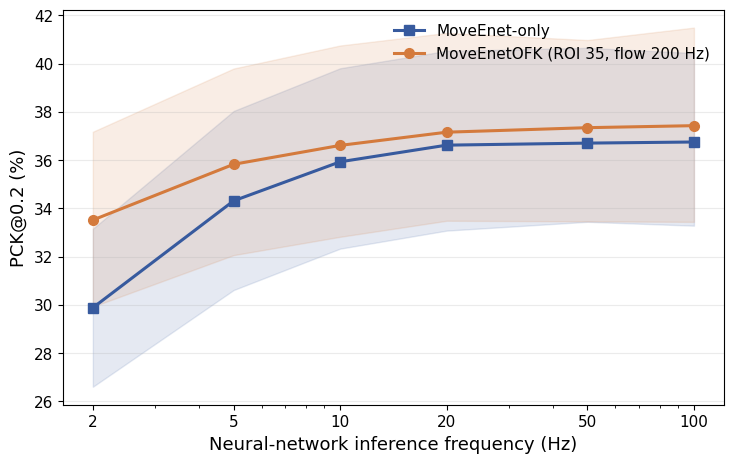

In [10]:
rates = sorted(summary.net_hz.unique())
fig, ax = plt.subplots(figsize=FIGSIZE)
for method in METHODS:
    group = summary[summary.method == method].set_index('net_hz').loc[rates]
    ax.plot(rates, group.pck02_percent, color=COLORS[method],
            marker=MARKERS[method], linewidth=LINE_WIDTH,
            markersize=MARKER_SIZE, label=LABELS[method])
    if SHOW_CI:
        ax.fill_between(rates, group.pck02_percent_ci_low.to_numpy(dtype=float),
                        group.pck02_percent_ci_high.to_numpy(dtype=float),
                        color=COLORS[method], alpha=.13)
ax.set_xscale('log')
ax.set_xticks(rates)
ax.set_xticklabels(['{:g}'.format(v) for v in rates])
ax.set_xlabel('Neural-network inference frequency (Hz)')
ax.set_ylabel('PCK@0.2 (%)')
ax.grid(axis='y', alpha=.25)
ax.legend(frameon=False)
fig.tight_layout()
if SAVE_FIGURES:
    for extension in FIGURE_FORMATS:
        fig.savefig(OUT / 'pck02_vs_network_rate.{}'.format(extension), dpi=DPI, bbox_inches='tight')
plt.show()

## 10. Figure 2 — MPJPE vs network inference frequency

Each valid GT joint counts as one observation. The network-rate axis, rendering style, figure sizes and output names match the previous notebook.

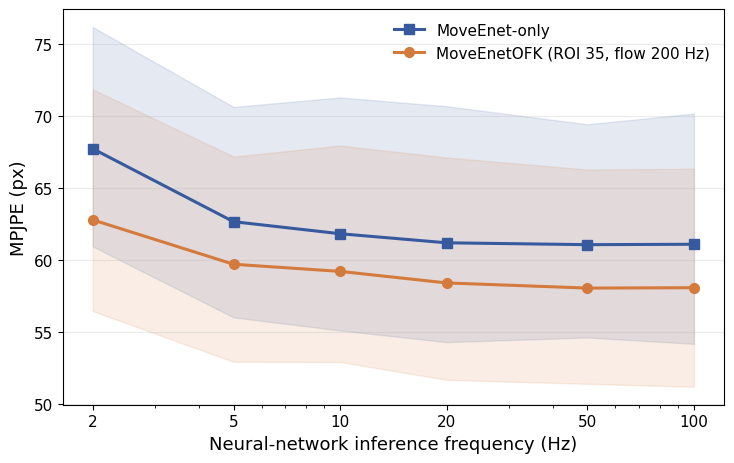

In [11]:
fig, ax = plt.subplots(figsize=FIGSIZE)
for method in METHODS:
    group = summary[summary.method == method].set_index('net_hz').loc[rates]
    ax.plot(rates, group.mpjpe_px, color=COLORS[method],
            marker=MARKERS[method], linewidth=LINE_WIDTH,
            markersize=MARKER_SIZE, label=LABELS[method])
    if SHOW_CI:
        ax.fill_between(rates, group.mpjpe_px_ci_low.to_numpy(dtype=float),
                        group.mpjpe_px_ci_high.to_numpy(dtype=float),
                        color=COLORS[method], alpha=.13)
ax.set_xscale('log')
ax.set_xticks(rates)
ax.set_xticklabels(['{:g}'.format(v) for v in rates])
ax.set_xlabel('Neural-network inference frequency (Hz)')
ax.set_ylabel('MPJPE (px)')
ax.grid(axis='y', alpha=.25)
ax.legend(frameon=False)
fig.tight_layout()
if SAVE_FIGURES:
    for extension in FIGURE_FORMATS:
        fig.savefig(OUT / 'mpjpe_vs_network_rate.{}'.format(extension), dpi=DPI, bbox_inches='tight')
plt.show()

## 11. Per-joint MPJPE at 5 Hz (diagnostic)

Interpret joint names cautiously until the provisional GT marker-to-joint mapping is verified.

method,"MoveEnetOFK (ROI 35, flow 200 Hz)",MoveEnet-only
joint,,
Head,68.17,71.31
Right shoulder,48.78,52.50
Left shoulder,50.38,54.05
Right elbow,58.26,61.88
Left elbow,58.25,61.98
Left hip,59.81,61.80
Right hip,54.33,56.64
Right wrist,86.44,90.48
Left wrist,79.57,83.48


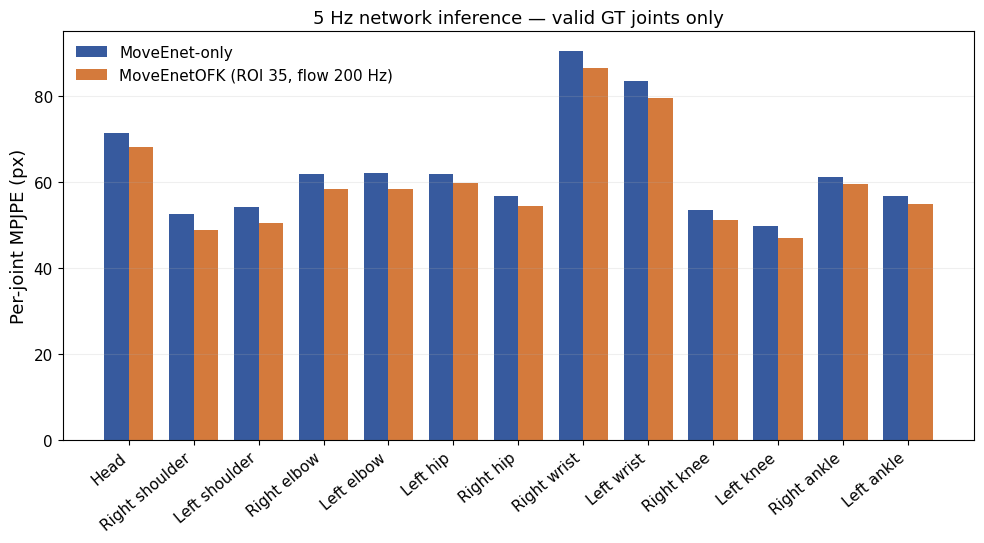

In [12]:
joint_5hz = joints[np.isclose(joints.net_hz, 5.)].copy()
require(not joint_5hz.empty, 'No per-joint 5 Hz data')
per_joint = joint_5hz.groupby(['joint', 'method'], as_index=False).agg(
    error_sum=('sum_error_px', 'sum'), joint_n=('valid_joints', 'sum'))
per_joint['mpjpe_px'] = np.divide(per_joint.error_sum, per_joint.joint_n)
joint_table = per_joint.pivot(index='joint', columns='method', values='mpjpe_px').reindex(JOINT_NAMES)
display(joint_table.rename(columns=LABELS).round(2))

fig, ax = plt.subplots(figsize=(10, 5.6))
x = np.arange(len(JOINT_NAMES))
width = .38
for offset, method in [(-.5, 'moveenet_only'), (.5, 'moveenet_ofk')]:
    ax.bar(x + offset*width, joint_table[method], width,
           color=COLORS[method], label=LABELS[method])
ax.set_xticks(x)
ax.set_xticklabels(JOINT_NAMES, rotation=40, ha='right')
ax.set_ylabel('Per-joint MPJPE (px)')
ax.set_title('5 Hz network inference — valid GT joints only')
ax.grid(axis='y', alpha=.2)
ax.legend(frameon=False)
fig.tight_layout()
if SAVE_FIGURES:
    for extension in FIGURE_FORMATS:
        fig.savefig(OUT / 'per_joint_mpjpe_5hz.{}'.format(extension), dpi=DPI, bbox_inches='tight')
plt.show()

## 12. Interpretation and limitations

1. This notebook **does not** change the training/inference or the stored predictions. It recomputes the metrics from the same 708 CSVs.
2. GT coordinates outside the sensor frame are excluded; the dataset may contain projected markers that are physically outside the field of view, sentinel values for missing markers, or both. Neither is a usable on-screen joint target.
3. The GT has nonuniform timestamps; interpolation uses each original timestamp, not an assumed regular 100 Hz or 200 Hz grid. The maximum bracketing gap is explicit.
4. PCK requires a valid torso length. When one of the two reference markers is invalid, **MPJPE may still be defined** for other joints, whereas PCK is excluded at that timestamp.
5. **Before publication:** verify `PROJECTION_TO_moveenet` anatomically (marker location vs joint semantics) and confirm `GT_TIME_OFFSET_S`. Those were provisional in the original notebook and remain so.
6. For strict comparison with the previous all-13-valid-row protocol, consider an additional sensitivity analysis restricted to timestamps where all joints are valid. The current primary protocol uses **per-joint masking** to retain usable observations without inventing GT.

In [13]:
print('Total recordings:', len(manifest))
print('Method/period runs:', len(samples))
print('Raw GT nonfinite annotations:', int(gt_quality.gt_nonfinite_annotations.sum()))
print('Raw GT out-of-frame annotations:', int(gt_quality.gt_out_of_frame_annotations.sum()))
print('Joint observations used for MPJPE (over all methods/rates):', int(samples.valid_joints.sum()))
print('Joint observations used for PCK (over all methods/rates):', int(samples.valid_pck_joints.sum()))
print('\nPaired OFK improvements (positive = better):')
print(deltas[['net_hz', 'pooled_mpjpe_reduction_px',
              'pooled_pck_improvement_pp']].to_string(index=False,
                                                      float_format=lambda v: '{:.3f}'.format(v)))
print('\nOutputs:', OUT)
print('CAUTION: GT joint mapping and GT time offset remain provisional.')

Total recordings: 59
Method/period runs: 708
Raw GT nonfinite annotations: 0
Raw GT out-of-frame annotations: 2678
Joint observations used for MPJPE (over all methods/rates): 18824556
Joint observations used for PCK (over all methods/rates): 18806724

Paired OFK improvements (positive = better):
 net_hz  pooled_mpjpe_reduction_px  pooled_pck_improvement_pp
  2.000                      4.947                      3.637
  5.000                      2.959                      1.515
 10.000                      2.618                      0.680
 20.000                      2.788                      0.537
 50.000                      3.018                      0.640
100.000                      3.020                      0.677

Outputs: /data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA/analysis_2d_gt_expa_masked_v2
CAUTION: GT joint mapping and GT time offset remain provisional.
